# Telco Customer Churn Prediction
### End-to-End Machine Learning Project

**Author:** Waseem Said Mahmoud
**Type:** Binary classification (will the customer leave or stay?)
**Dataset:** Telco Customer Churn (Kaggle)

---
**Notebook steps**
1. Choose the dataset
2. Frame the business problem
3. Load and understand the data
4. Split the data (train / validation / test)
5. EDA
6. Data cleaning
7. Feature engineering
8. Prepare data for ML
9. Train 5 models
10. Best model + hyperparameter tuning
11. Final testing

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42   # same seed everywhere -> reproducible results

## 1️⃣ Choose Your Dataset

**Dataset:** *Telco Customer Churn* (Kaggle: `blastchar/telco-customer-churn`, sample data from IBM).

- **Problem domain:** Telecommunications (phone and internet company).
- **What the data represents:** Each row is **one customer**. The columns describe the customer
  (gender, senior citizen, partner, dependents), the services he/she has (phone, internet, security, tech support, streaming),
  the account (contract type, payment method, monthly and total charges, tenure in months) and the target column **`Churn`**
  (did the customer leave the company in the last month?).
- **Why I chose it:** Customer churn is one of the most common business problems in companies.
  The data is easy to understand, but it has real challenges: the classes are **imbalanced**,
  there are **numeric and categorical** columns, and there is a column with a data-type problem (`TotalCharges`).
  So it is a good dataset to practice every step of an ML project.

## 2️⃣ Frame the Business Problem

- **Goal:** Predict whether a customer will **churn** (leave the company) or stay, using his/her profile, services and account data.
- **Why it is important:** Getting a new customer costs much more than keeping an existing one.
  If the company knows **early** which customers are likely to leave, it can contact them with an offer
  (discount, better contract, free tech support) and save revenue.
- **Type of problem:** **Classification** (binary: `Churn = 1` or `0`).
- **Technical metrics:**
  - **F1-score (churn class) – main metric.** Only about 27% of customers churn, so the data is imbalanced.
    Accuracy is misleading (a model that says "nobody leaves" gets ~73% accuracy and catches zero churners).
    F1 balances **precision** (how many of the customers we flag really leave) and **recall** (how many of the real churners we catch).
  - **ROC-AUC – second metric.** It shows how well the model ranks churners above non-churners, and it does not depend on the threshold.
  - **Recall** is also reported, because for the business, missing a real churner is usually more costly than sending an offer to someone who would stay.

**Problem statement:** *Build a classification model that predicts customer churn and maximizes the F1-score of the churn class (with ROC-AUC as a supporting metric).*

## 3️⃣ Load and Understand Your Data

In [2]:
# Kaggle file name. If you run it on Kaggle, the second path is used.
DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Summary table of the dataset details
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique(),
    "example_value": df.iloc[0],
})
summary

,dtype,missing_values,unique_values,example_value
customerID,str,0,7043,7590-VHVEG
gender,str,0,2,Female
SeniorCitizen,int64,0,2,0
Partner,str,0,2,Yes
Dependents,str,0,2,No
tenure,int64,0,73,1
PhoneService,str,0,2,No
MultipleLines,str,0,3,No phone service
InternetService,str,0,3,DSL
OnlineSecurity,str,0,3,No


In [4]:
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("\nTarget variable (Churn):")
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

Duplicate customer IDs: 0

Target variable (Churn):
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


**What we learned**
- **7,043 customers** and **21 columns**: 1 ID column, 1 target (`Churn`) and 19 features.
- **Target:** `Churn` (Yes/No). It is **imbalanced** (about 26.5% Yes).
- **Numeric columns:** `tenure`, `MonthlyCharges`, `TotalCharges`, and `SeniorCitizen` (it is already 0/1).
- **Problem found:** `TotalCharges` has type *object* (text) instead of a number. It has hidden blank values (spaces) that `isna()` does not see.
  We will fix it in the cleaning step.
- `customerID` is only an identifier, so it will not be used for training.

## 4️⃣ Split Your Data

We split **before** any EDA, cleaning or feature engineering, so that the validation and test sets stay unseen.

- **Train 60%**: to learn (fit) preprocessing and models.
- **Validation 20%**: to compare models and tune.
- **Test 20%**: used **only once** at the end.
- We use `stratify` so the churn rate is the same in the three sets, and `random_state` for reproducibility.

In [5]:
# The target is converted to 0/1 (this does not learn anything from the data)
df["Churn"] = (df["Churn"] == "Yes").astype(int)

# 1) 60% train, 40% temporary
train_df, temp_df = train_test_split(
    df, test_size=0.40, stratify=df["Churn"], random_state=RANDOM_STATE)
# 2) split the temporary part in half: 20% validation, 20% test
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["Churn"], random_state=RANDOM_STATE)

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name:10s} rows = {len(part):5d} | churn rate = {part['Churn'].mean():.3f}")

Train      rows =  4225 | churn rate = 0.265
Validation rows =  1409 | churn rate = 0.265
Test       rows =  1409 | churn rate = 0.265


> **Reminder:** From now on, every statistic (means, categories, scaling values, outlier limits) is learned from **train only**.
> The EDA below also uses **train only**.

## 5️⃣ EDA (Exploratory Data Analysis)

EDA is done on the **train set only**. For plotting, we make a temporary copy and convert `TotalCharges` to a number.

In [6]:
eda = train_df.copy()
eda["TotalCharges"] = pd.to_numeric(eda["TotalCharges"].str.strip(), errors="coerce")
eda["Churn_label"] = eda["Churn"].map({0: "No", 1: "Yes"})
palette = {"No": "#4C72B0", "Yes": "#DD5555"}

### Plot 1: Class imbalance (target distribution)

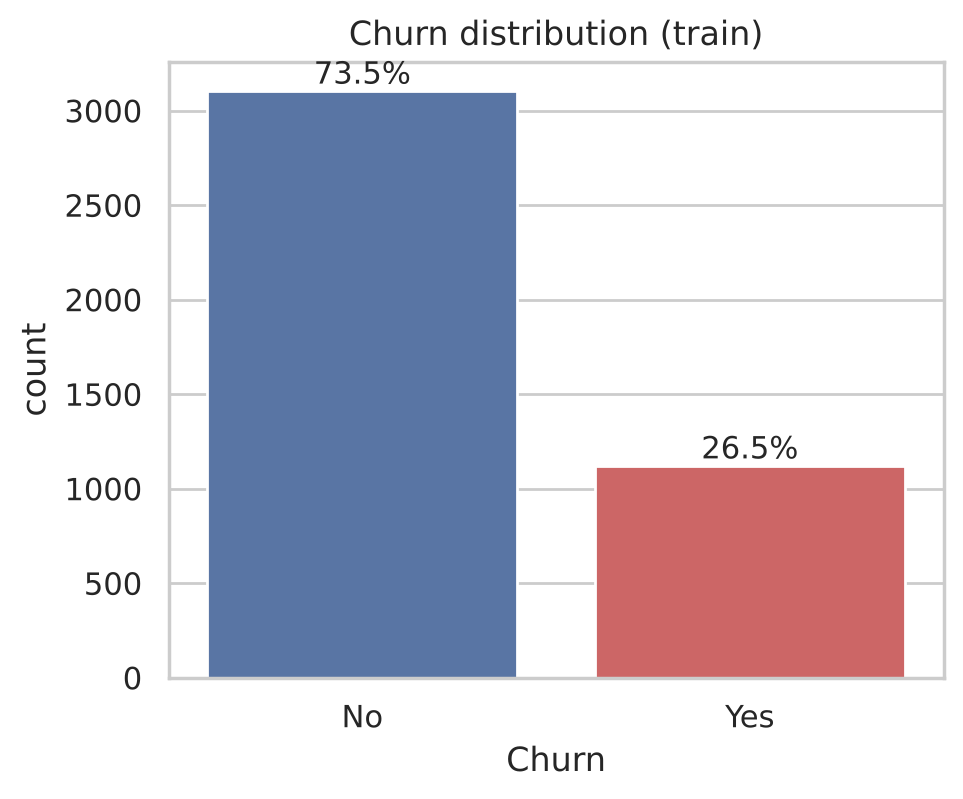

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=eda, x="Churn_label", order=["No", "Yes"], palette=palette, ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height()/len(eda):.1%}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=11)
ax.set_title("Churn distribution (train)")
ax.set_xlabel("Churn")
plt.show()

**Insight:** About 1 customer in 4 churns. The classes are imbalanced, so accuracy is not enough. We will use F1 / ROC-AUC and `class_weight='balanced'`.

### Plot 2: Churn rate by contract type

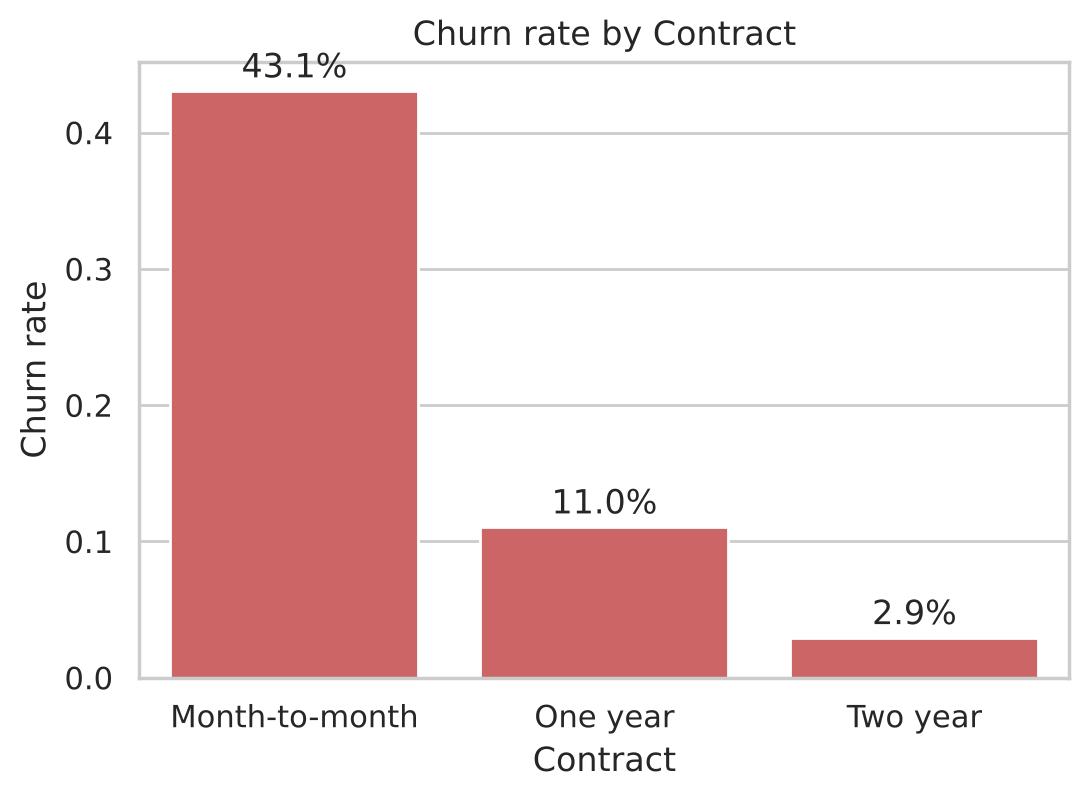

In [8]:
rate = eda.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=rate.index, y=rate.values, color="#DD5555", ax=ax)
for i, v in enumerate(rate.values):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
ax.set_ylabel("Churn rate"); ax.set_title("Churn rate by Contract")
plt.show()

**Insight:** Month-to-month customers churn a lot (~43%), one-year customers ~11%, and two-year customers only ~3%. Contract type is one of the strongest signals.

### Plot 3: Tenure distribution for churned vs. stayed customers

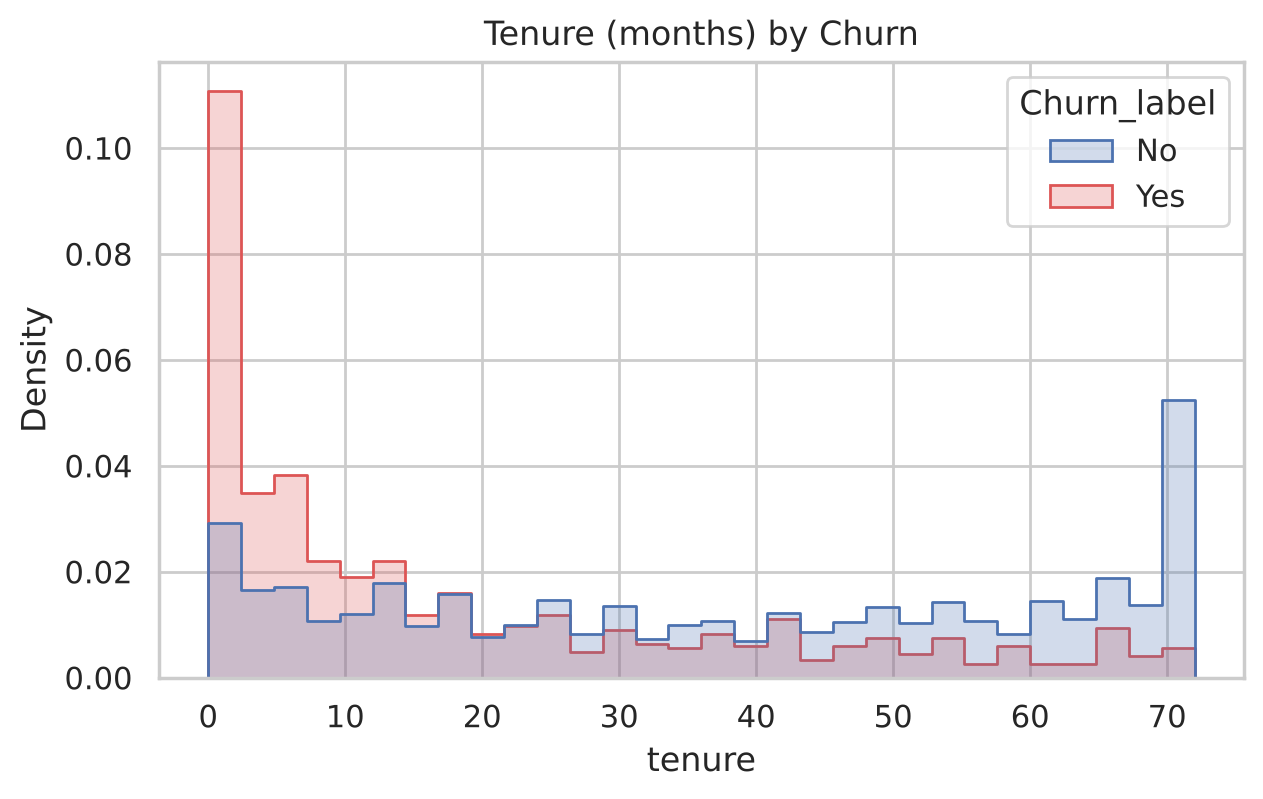

Churn_label
No     38.0
Yes    10.0
Name: tenure, dtype: float64


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=eda, x="tenure", hue="Churn_label", bins=30, palette=palette,
             element="step", stat="density", common_norm=False, ax=ax)
ax.set_title("Tenure (months) by Churn")
plt.show()
print(eda.groupby("Churn_label")["tenure"].median())

**Insight:** Churners are mostly **new** customers (median tenure ~10 months vs. ~38 months for customers who stayed). The risk is highest in the first year.

### Plot 4: Monthly charges for churned vs. stayed customers

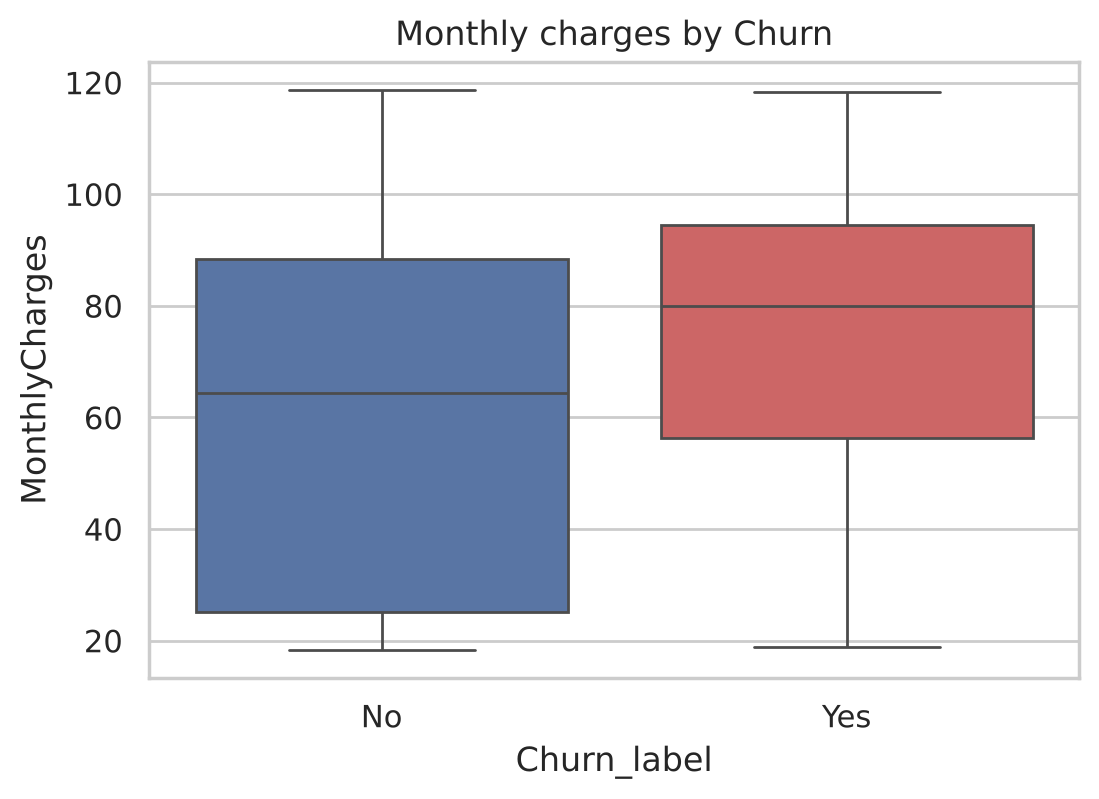

Churn_label
No     64.4
Yes    80.0
Name: MonthlyCharges, dtype: float64


In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=eda, x="Churn_label", y="MonthlyCharges", order=["No", "Yes"], palette=palette, ax=ax)
ax.set_title("Monthly charges by Churn")
plt.show()
print(eda.groupby("Churn_label")["MonthlyCharges"].median())

**Insight:** Customers who churn pay more per month (median ~80 vs. ~64). Higher bills increase the chance of leaving.

### Plot 5: Churn rate by internet service and by payment method

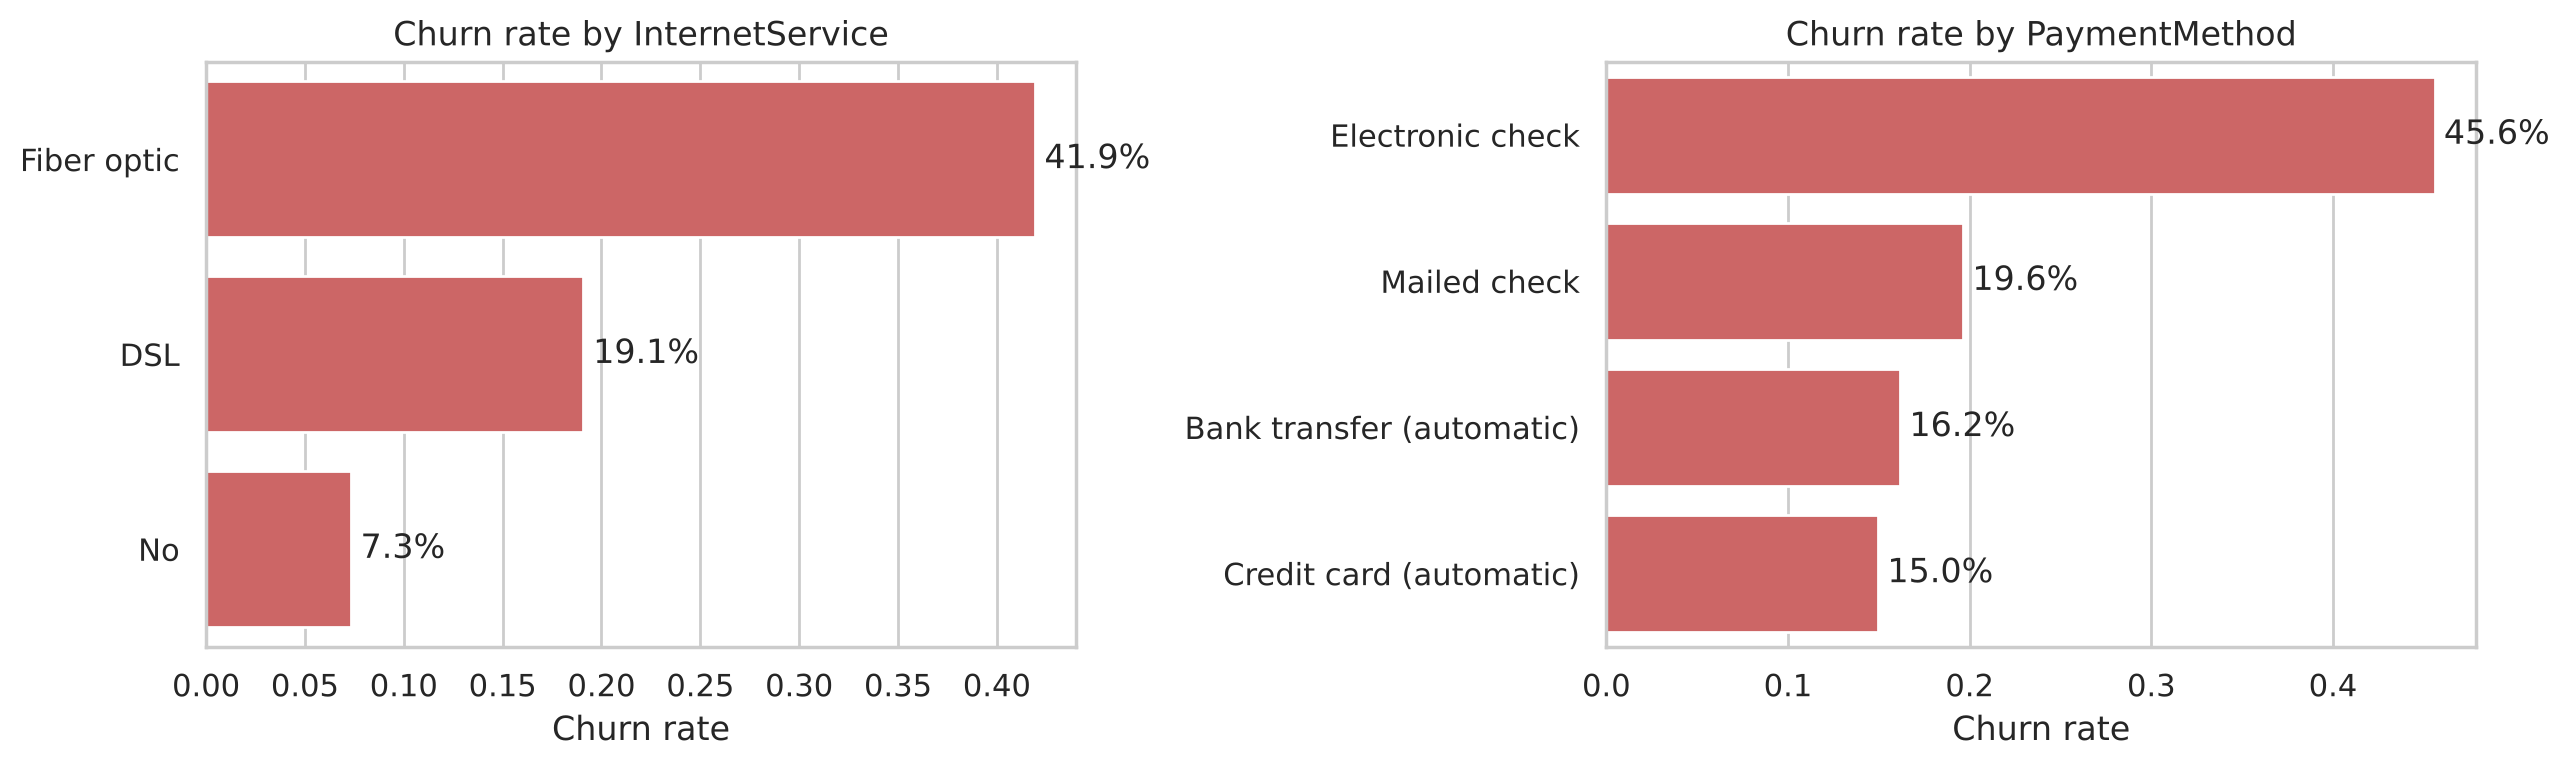

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["InternetService", "PaymentMethod"]):
    rate = eda.groupby(col)["Churn"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, color="#DD5555", ax=ax)
    for i, v in enumerate(rate.values):
        ax.text(v + 0.005, i, f"{v:.1%}", va="center")
    ax.set_xlabel("Churn rate"); ax.set_ylabel(""); ax.set_title(f"Churn rate by {col}")
plt.tight_layout(); plt.show()

**Insight:** **Fiber optic** customers churn much more (~42%) than DSL (~19%) or no-internet customers (~7%).
Customers paying by **electronic check** churn the most (~46%), while automatic payments (bank transfer / credit card) are around 15-16%.

### Plot 6: Correlation between numeric features and churn

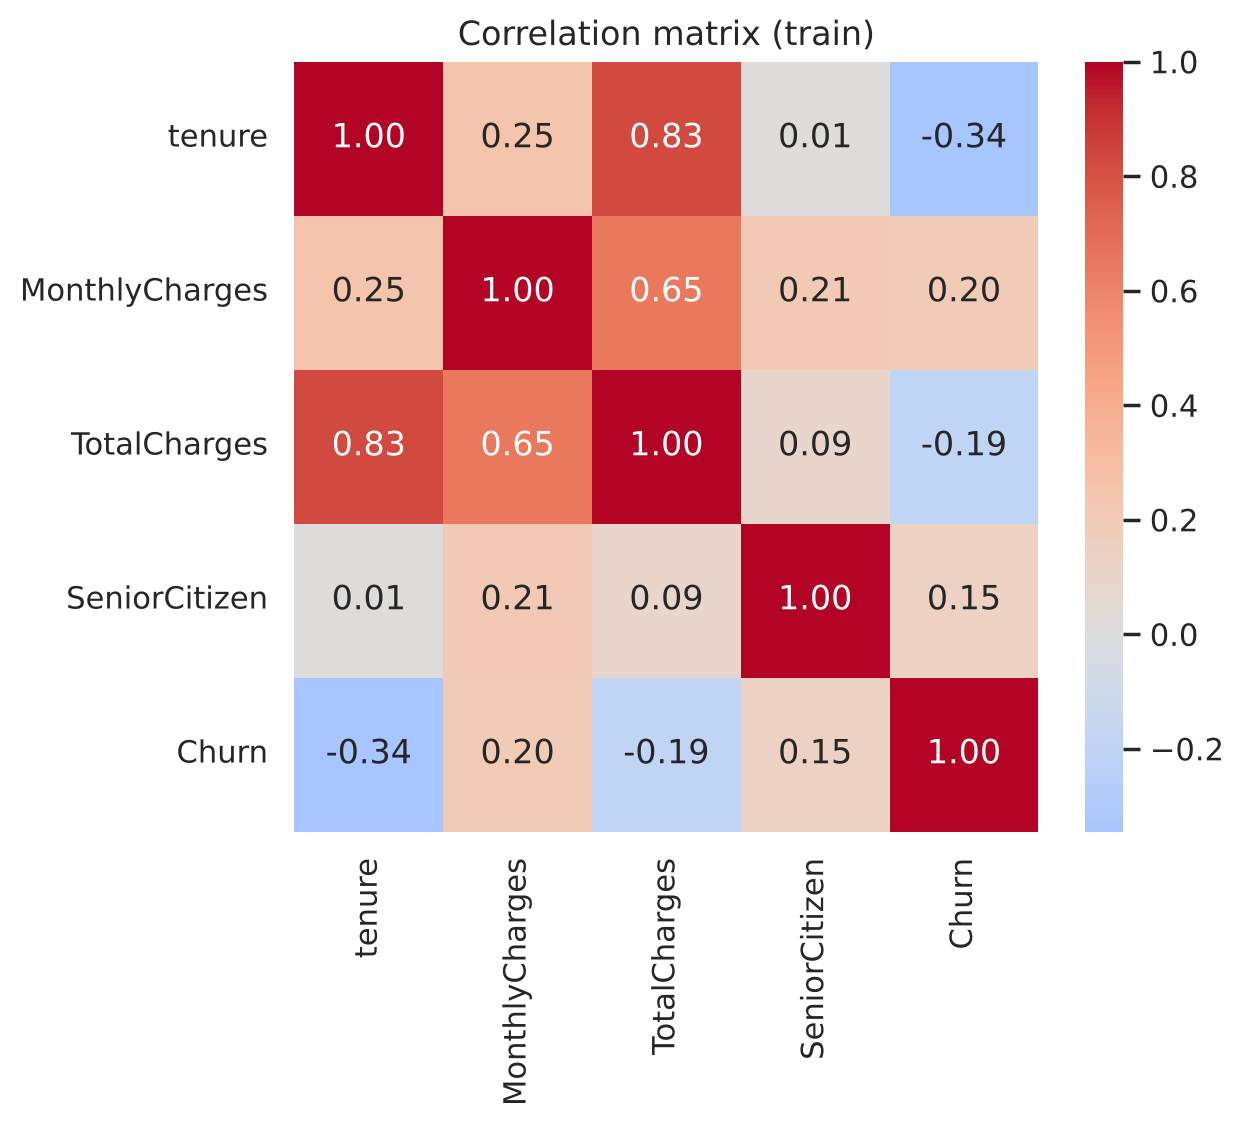

In [12]:
num_cols_eda = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(eda[num_cols_eda].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (train)")
plt.show()

**Insight:** `tenure` has the strongest (negative) correlation with churn (-0.34): longer tenure means less churn.
`TotalCharges` is highly correlated with `tenure` (0.83) because it is roughly *tenure x monthly charge*.
This is a multicollinearity warning for linear models, so we will log-transform it and keep it as one feature.

### Extra checks: other features, outliers

In [13]:
# Does gender matter? Do other simple features matter?
for col in ["gender", "SeniorCitizen", "Partner", "PaperlessBilling", "TechSupport"]:
    print(eda.groupby(col)["Churn"].mean().round(3).to_frame("churn_rate"), "\n")

        churn_rate
gender            
Female        0.26
Male          0.27 

               churn_rate
SeniorCitizen            
0                   0.237
1                   0.413 

         churn_rate
Partner            
No            0.330
Yes           0.196 

                  churn_rate
PaperlessBilling            
No                     0.159
Yes                    0.341 

                     churn_rate
TechSupport                    
No                        0.424
No internet service       0.073
Yes                       0.150 



In [14]:
# Outlier check with the IQR rule (limits learned from train only)
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = eda[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((eda[col] < low) | (eda[col] > high)).sum()
    print(f"{col:15s} IQR limits = [{low:8.1f}, {high:8.1f}]  outliers = {n_out}  skew = {eda[col].skew():.2f}")

tenure          IQR limits = [   -60.0,    124.0]  outliers = 0  skew = 0.24
MonthlyCharges  IQR limits = [   -46.6,    172.1]  outliers = 0  skew = -0.22
TotalCharges    IQR limits = [ -4792.0,   9060.1]  outliers = 0  skew = 0.95


**Insights from the extra checks**
- `gender` has almost no effect (26% vs. 27%), so it is not useful and we will drop it.
- Senior citizens (~41%), customers without a partner (~33%), paperless billing (~34%) and customers **without** tech support (~42% vs. ~15%) churn more.
- **No outliers** were found by the IQR rule in the numeric columns, so we do not remove any rows (removing rows without a reason would lose information).
- `TotalCharges` is right-skewed (skew ~0.95), so a log transform will help.

**Summary of the EDA:** the typical churner is a **new** customer on a **month-to-month** contract, with **fiber optic** internet, **electronic check** payment, **no tech support**, and a **high monthly bill**.

## 6️⃣ Data Cleaning

We write **one function** `clean_data()` and apply the **same function** to train, validation and test.
The cleaning rules below are fixed rules (they do not learn anything from the data), so there is no leakage.

1. **Fix data type:** `TotalCharges` text -> number.
2. **Missing values:** After conversion, the blank `TotalCharges` rows become `NaN`. All of them have `tenure = 0` (brand-new customers who have not been billed yet), so the correct value is **0**.
3. **Inconsistent labels:** `"No internet service"` and `"No phone service"` mean the same as `"No"` for those service columns (the information is already in `InternetService` and `PhoneService`).
4. **Binary columns:** Yes/No -> 1/0.
5. **Drop** `customerID` (identifier, no predictive value).
6. **Outliers:** none were found in EDA, so nothing is removed.

In [15]:
SERVICE_COLS = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]
BINARY_COLS = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"] + SERVICE_COLS


def clean_data(data):
    data = data.copy()

    # 1) Fix data type
    data["TotalCharges"] = pd.to_numeric(data["TotalCharges"].astype(str).str.strip(), errors="coerce")

    # 2) Missing values: new customers (tenure == 0) have not paid anything yet
    data.loc[data["TotalCharges"].isna() & (data["tenure"] == 0), "TotalCharges"] = 0.0

    # 3) Make the labels consistent
    for col in SERVICE_COLS:
        data[col] = data[col].replace({"No internet service": "No", "No phone service": "No"})

    # 4) Yes/No -> 1/0
    for col in BINARY_COLS:
        data[col] = data[col].map({"Yes": 1, "No": 0})

    # 5) Drop the identifier
    data = data.drop(columns=["customerID"])
    return data


train_clean = clean_data(train_df)
val_clean = clean_data(val_df)
test_clean = clean_data(test_df)

# Checks
for name, part in [("Train", train_clean), ("Validation", val_clean), ("Test", test_clean)]:
    print(f"{name:10s} shape = {part.shape} | missing values = {part.isna().sum().sum()}")
print("\nTotalCharges dtype:", train_clean["TotalCharges"].dtype)

Train      shape = (4225, 20) | missing values = 0
Validation shape = (1409, 20) | missing values = 0
Test       shape = (1409, 20) | missing values = 0

TotalCharges dtype: float64


## 7️⃣ Feature Engineering

New features (they use only the same row, so there is **no leakage**):

| New feature | How it is made | Why |
|---|---|---|
| `num_addon_services` | count of add-on services (security, backup, device protection, tech support, streaming TV/movies) | Customers with more services are more "attached" to the company. |
| `has_protection` | 1 if the customer has `OnlineSecurity` **or** `TechSupport` | EDA showed that customers without support churn much more. |
| `is_autopay` | 1 if payment method is automatic (bank transfer / credit card) | Automatic payment has a very low churn rate; electronic check has the highest. |
| `tenure_group` | tenure bins: 0-12, 13-24, 25-48, 49-72 months | The risk is not linear: the first year is the most dangerous. |

Other transformations:
- **Log transform:** `TotalCharges` -> `TotalCharges_log` (it is right-skewed).
- **Drop:** `gender` (no relation with churn in EDA).

In [16]:
ADDON_COLS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
              "StreamingTV", "StreamingMovies"]


def add_features(data):
    data = data.copy()

    data["num_addon_services"] = data[ADDON_COLS].sum(axis=1)
    data["has_protection"] = ((data["OnlineSecurity"] == 1) | (data["TechSupport"] == 1)).astype(int)
    data["is_autopay"] = data["PaymentMethod"].isin(
        ["Bank transfer (automatic)", "Credit card (automatic)"]).astype(int)
    data["tenure_group"] = pd.cut(data["tenure"], bins=[-1, 12, 24, 48, 72],
                                  labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)

    # log transform for the skewed column
    data["TotalCharges_log"] = np.log1p(data["TotalCharges"])
    data = data.drop(columns=["TotalCharges"])

    # drop an irrelevant feature
    data = data.drop(columns=["gender"])
    return data


train_fe = add_features(train_clean)
val_fe = add_features(val_clean)
test_fe = add_features(test_clean)

train_fe[["num_addon_services", "has_protection", "is_autopay", "tenure_group", "TotalCharges_log"]].head()

,num_addon_services,has_protection,is_autopay,tenure_group,TotalCharges_log
2833,3,1,1,49-72,8.298652
846,6,1,1,49-72,8.605241
2501,0,0,0,49-72,7.211852
6729,4,1,1,49-72,8.508001
2903,2,1,0,0-12,6.071315


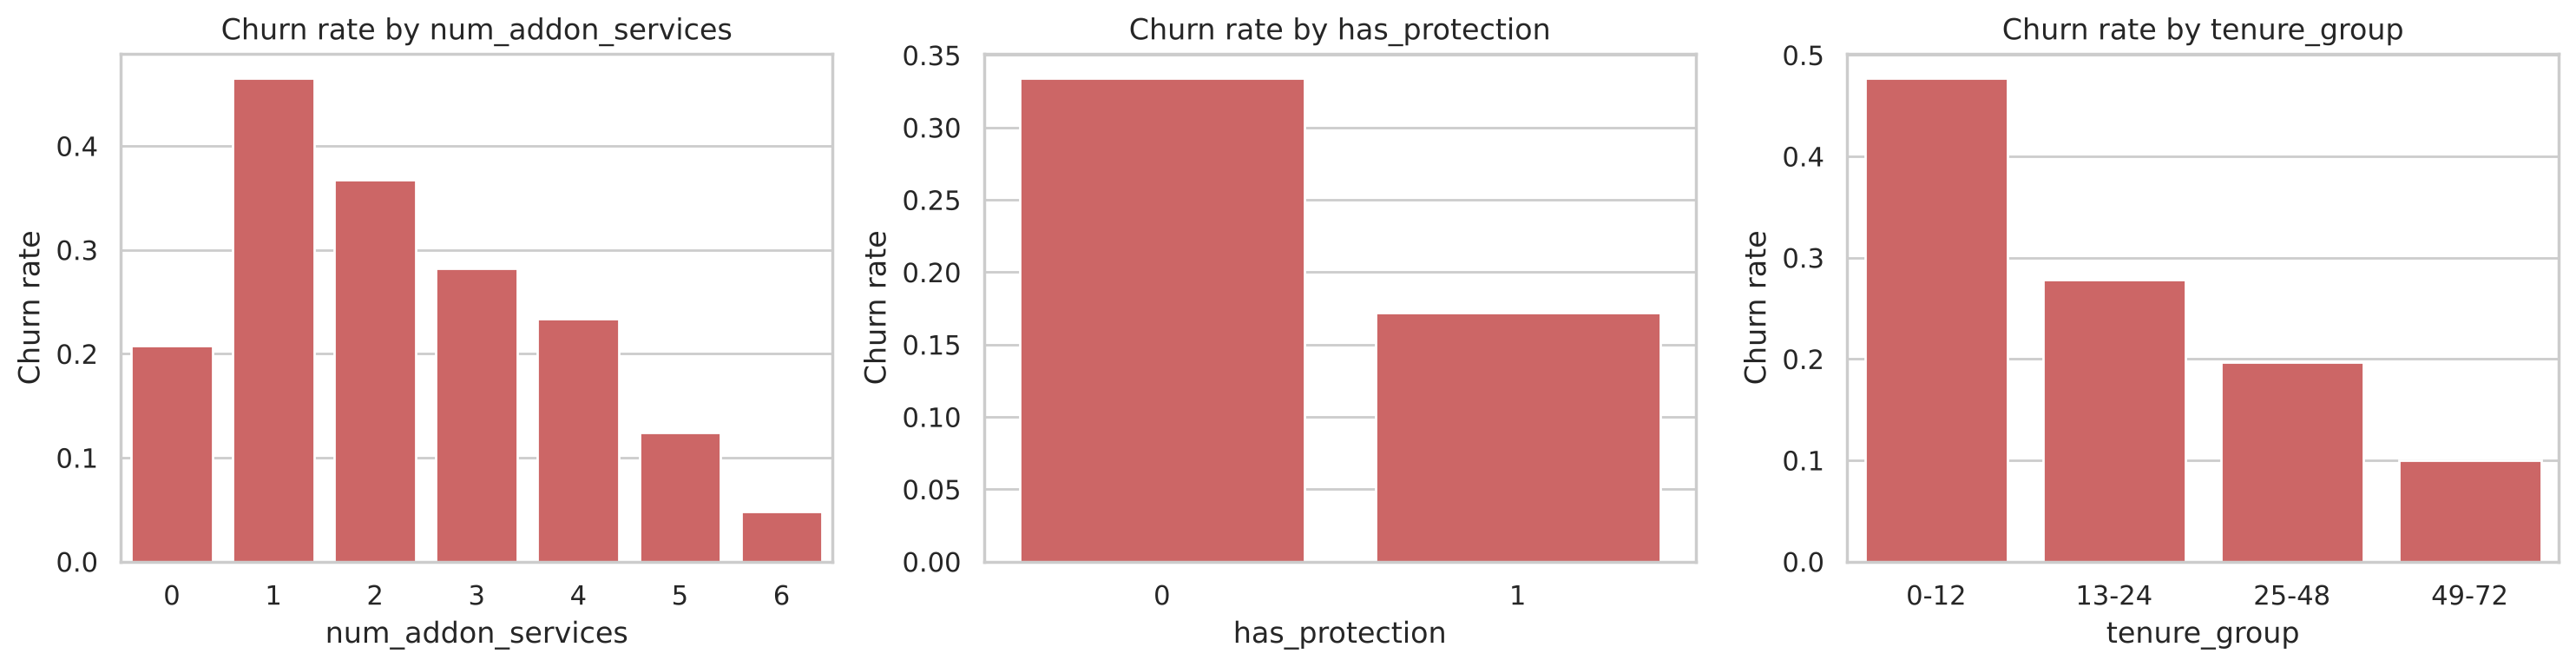

Skew of TotalCharges before log: 0.95
Skew of TotalCharges after  log: -0.82


In [17]:
# Do the new features really help to separate churners? (train only)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["num_addon_services", "has_protection", "tenure_group"]):
    order = sorted(train_fe[col].unique(), key=lambda v: (str(v).zfill(5)))
    rate = train_fe.groupby(col)["Churn"].mean().reindex(order)
    sns.barplot(x=rate.index.astype(str), y=rate.values, color="#DD5555", ax=ax)
    ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("Churn rate")
plt.tight_layout(); plt.show()

print("Skew of TotalCharges before log:", round(train_clean["TotalCharges"].skew(), 2))
print("Skew of TotalCharges after  log:", round(train_fe["TotalCharges_log"].skew(), 2))

**Result:** The new features show clear patterns (churn is much lower for customers with protection services and with longer tenure).
The log transform compresses the long tail of very large `TotalCharges` values (the skew changes from about +0.95 to about -0.82, so it is not perfectly normal, but the extreme values are much less dominant). This helps the linear and distance-based models (Logistic Regression, SVM).

## 8️⃣ Prepare Your Data for ML

1. Separate **features (X)** and **target (y)**.
2. **Scaling** (`StandardScaler`) for the numeric columns, and **One-Hot Encoding** for the multi-category columns.
3. **Important (no data leakage):** `fit` on **train only**, then `transform` train, validation and test.

In [18]:
TARGET = "Churn"
NUMERIC_COLS = ["tenure", "MonthlyCharges", "TotalCharges_log", "num_addon_services"]
CATEGORICAL_COLS = ["InternetService", "Contract", "PaymentMethod", "tenure_group"]

# 1) features and target
X_train, y_train = train_fe.drop(columns=TARGET), train_fe[TARGET]
X_val, y_val = val_fe.drop(columns=TARGET), val_fe[TARGET]
X_test, y_test = test_fe.drop(columns=TARGET), test_fe[TARGET]

# 2) fit on TRAIN only
scaler = StandardScaler().fit(X_train[NUMERIC_COLS])
encoder = OneHotEncoder(drop="first", sparse_output=False).fit(X_train[CATEGORICAL_COLS])


def prepare(X):
    num = pd.DataFrame(scaler.transform(X[NUMERIC_COLS]), columns=NUMERIC_COLS, index=X.index)
    cat = pd.DataFrame(encoder.transform(X[CATEGORICAL_COLS]),
                       columns=encoder.get_feature_names_out(CATEGORICAL_COLS), index=X.index)
    rest = X.drop(columns=NUMERIC_COLS + CATEGORICAL_COLS)   # columns that are already 0/1
    return pd.concat([num, rest, cat], axis=1)


# 3) transform train, validation and test with the same fitted objects
X_train_p = prepare(X_train)
X_val_p = prepare(X_val)
X_test_p = prepare(X_test)

print("Train :", X_train_p.shape, "| Validation:", X_val_p.shape, "| Test:", X_test_p.shape)
assert list(X_train_p.columns) == list(X_val_p.columns) == list(X_test_p.columns)
assert X_train_p.isna().sum().sum() == 0 and X_val_p.isna().sum().sum() == 0 and X_test_p.isna().sum().sum() == 0
print("Same columns in all sets, no missing values.")
print("\nScaler mean learned from TRAIN:", dict(zip(NUMERIC_COLS, scaler.mean_.round(2))))
X_train_p.head()

Train : (4225, 28) | Validation: (1409, 28) | Test: (1409, 28)
Same columns in all sets, no missing values.

Scaler mean learned from TRAIN: {'tenure': np.float64(32.44), 'MonthlyCharges': np.float64(64.89), 'TotalCharges_log': np.float64(6.94), 'num_addon_services': np.float64(2.07)}


,tenure,MonthlyCharges,TotalCharges_log,num_addon_services,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,has_protection,is_autopay,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_13-24,tenure_group_25-48,tenure_group_49-72
2833,1.362657,-0.123490,0.867830,0.496796,0,0,0,1,0,1,1,1,0,0,0,1,1,1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
846,1.322050,0.658110,1.062992,2.100284,0,0,0,1,0,1,1,1,1,1,1,1,1,1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2501,1.606299,-1.469029,0.176022,-1.106691,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
6729,1.443871,0.265661,1.001093,1.031292,0,1,1,1,0,0,0,1,1,1,1,1,1,1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2903,-0.830123,-0.969399,-0.549993,-0.037699,0,1,1,0,0,0,1,0,1,0,0,0,1,0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


**Leakage check:** The scaler mean and the encoder categories come from the train set only.
The validation and test sets are only transformed. Their rows never influenced any learned value.

## 9️⃣ Train 5 Different ML Models

| Model | Why we try it |
|---|---|
| Logistic Regression | simple, fast, interpretable baseline for classification |
| Decision Tree | easy to understand, captures non-linear rules |
| Random Forest | many trees, usually strong and stable |
| Gradient Boosting (`HistGradientBoostingClassifier`) | one of the best algorithms for tabular data |
| SVM (RBF kernel) | good with complex boundaries after scaling |

All models use `class_weight="balanced"` to deal with the imbalance (the minority class gets more weight).
We train on **train** and compare on the **validation** set.
A **dummy model** (always predicts "No churn") is added only as a reference line.

In [19]:
def get_scores(model, X):
    # probability or decision score, used for ROC-AUC
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def evaluate(model, X, y, threshold=None):
    scores = get_scores(model, X)
    # threshold=None -> the model's default decision rule
    pred = model.predict(X) if threshold is None else (scores >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "ROC-AUC": roc_auc_score(y, scores),
    }


models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    model.fit(X_train_p, y_train)
    val_scores = evaluate(model, X_val_p, y_val)
    train_f1 = f1_score(y_train, model.predict(X_train_p))
    rows.append({"Model": name, **val_scores, "Train F1": train_f1})

# reference line: always predict the majority class
dummy = DummyClassifier(strategy="most_frequent").fit(X_train_p, y_train)
dummy_pred = dummy.predict(X_val_p)
print("Dummy baseline on validation -> Accuracy: %.3f | F1: %.3f" % (
    accuracy_score(y_val, dummy_pred), f1_score(y_val, dummy_pred, zero_division=0)))

results = pd.DataFrame(rows).set_index("Model").sort_values("F1", ascending=False)
results.round(3)

Dummy baseline on validation -> Accuracy: 0.735 | F1: 0.000


,Accuracy,Precision,Recall,F1,ROC-AUC,Train F1
Model,,,,,,
Logistic Regression,0.750,0.518,0.826,0.637,0.862,0.641
SVM (RBF),0.752,0.522,0.807,0.634,0.838,0.668
Decision Tree,0.749,0.519,0.770,0.620,0.837,0.630
Gradient Boosting,0.749,0.520,0.727,0.606,0.839,0.815
Random Forest,0.777,0.574,0.620,0.596,0.831,0.992


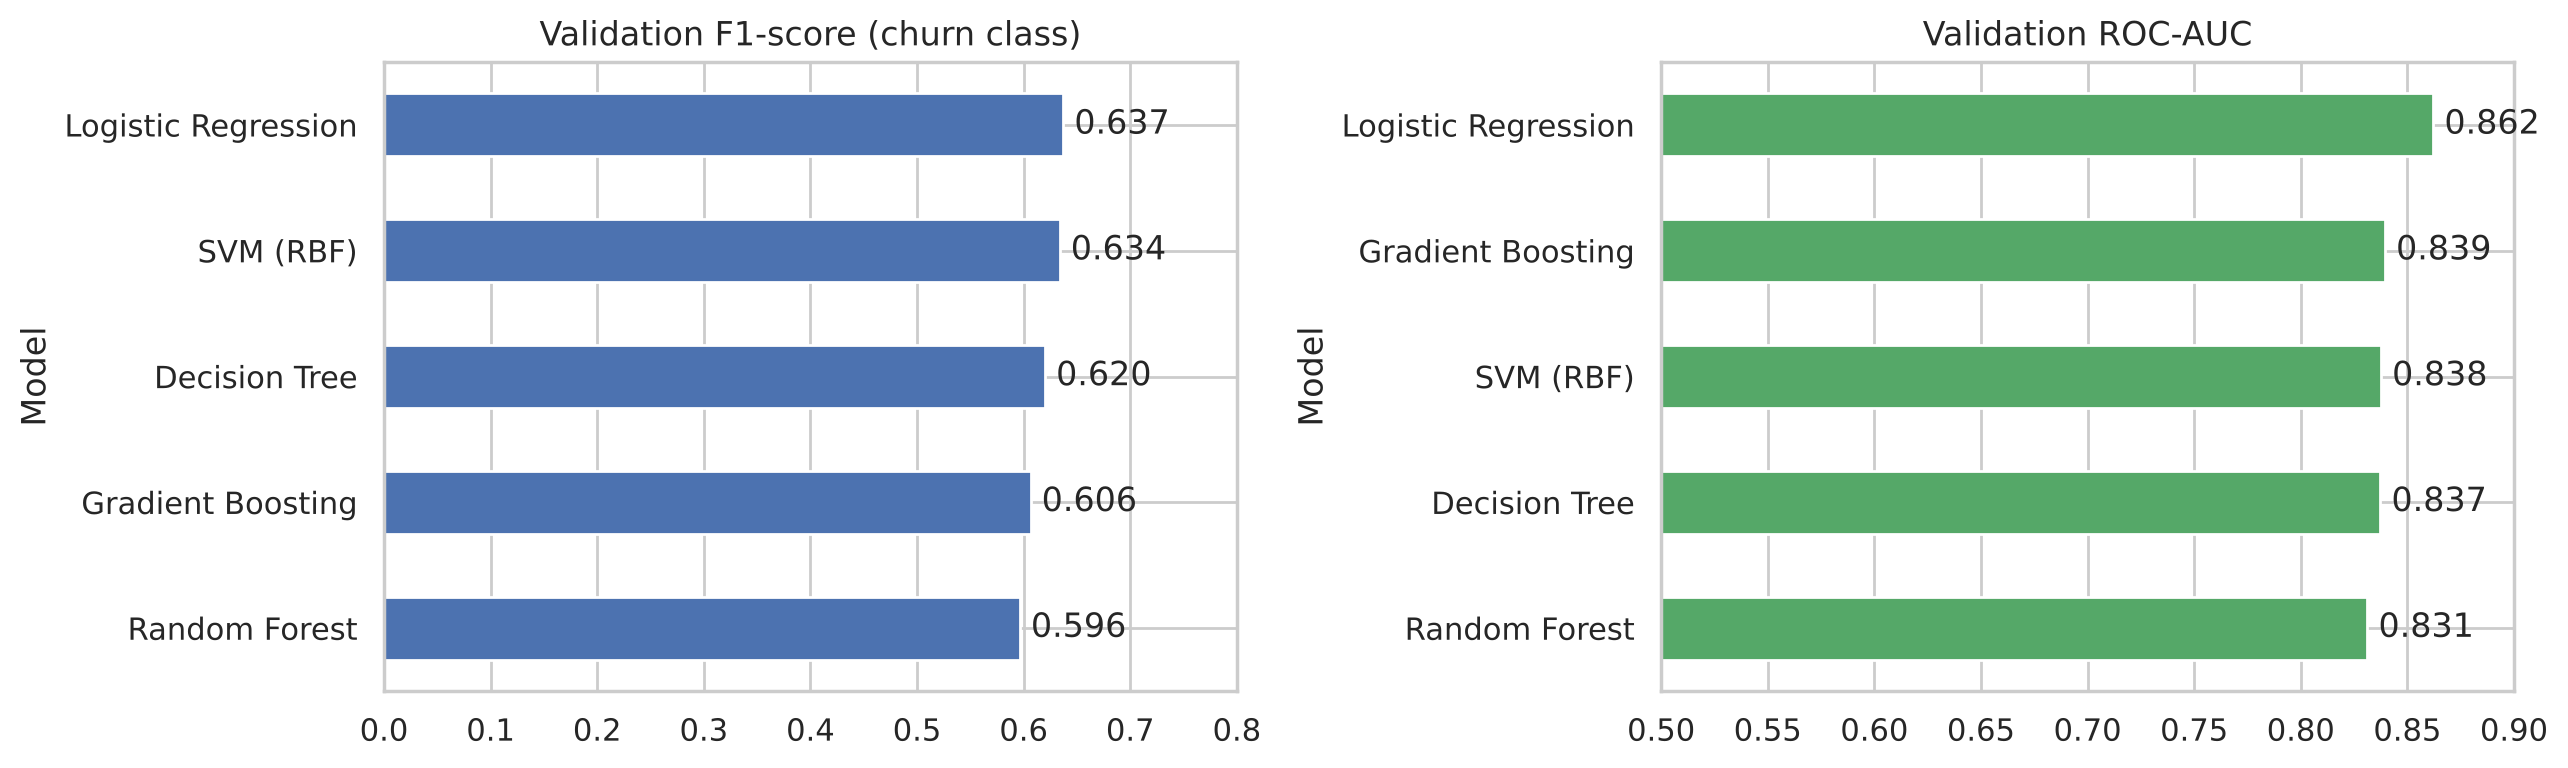

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results["F1"].sort_values().plot(kind="barh", color="#4C72B0", ax=axes[0])
axes[0].set_title("Validation F1-score (churn class)"); axes[0].set_xlim(0, 0.8)
results["ROC-AUC"].sort_values().plot(kind="barh", color="#55A868", ax=axes[1])
axes[1].set_title("Validation ROC-AUC"); axes[1].set_xlim(0.5, 0.9)
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{p.get_width():.3f}", (p.get_width(), p.get_y() + p.get_height()/2),
                    xytext=(4, 0), textcoords="offset points", va="center")
plt.tight_layout(); plt.show()

**Reading the table**
- All models are far better than the dummy baseline (F1 = 0).
- `Train F1` vs. `F1` (validation) shows **overfitting**. Random Forest and Gradient Boosting learn the train set very well, so the gap between train and validation is larger for them.
- We select the best model with the **validation F1** (ROC-AUC is used to check that the ranking is consistent).

## 🔟 Choose the Best Model + Hyperparameter Tuning

1. The best model is selected **automatically** from the validation F1-score.
2. **Tuning A – GridSearchCV:** 5-fold stratified cross-validation on the **train set** only (the validation set is not used inside the search, so the before/after comparison stays fair). Search metric: **F1**.
3. **Tuning B – decision threshold:** The default threshold gives many false alarms. We choose the threshold that maximizes F1 using **cross-validated predictions on train** (again, no validation or test data).
4. We compare three versions on the **validation set** and keep the best one: *default settings*, *grid search*, *grid search + threshold*.

In [21]:
best_name = results["F1"].idxmax()
print("Best model on validation (before tuning):", best_name)
print(results.loc[best_name, ["F1", "ROC-AUC", "Recall", "Precision"]].round(3).to_dict())

Best model on validation (before tuning): Logistic Regression
{'F1': 0.637, 'ROC-AUC': 0.862, 'Recall': 0.826, 'Precision': 0.518}


In [22]:
param_grids = {
    "Logistic Regression": {"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30], "penalty": ["l1", "l2"],
                            "solver": ["liblinear"], "class_weight": ["balanced", None, {0: 1, 1: 2}]},
    "Decision Tree": {"max_depth": [3, 4, 5, 6, 8], "min_samples_leaf": [5, 20, 50],
                      "criterion": ["gini", "entropy"]},
    "Random Forest": {"n_estimators": [200, 400], "max_depth": [5, 8, 12],
                      "min_samples_leaf": [3, 5, 10], "max_features": ["sqrt", 0.5]},
    "Gradient Boosting": {"learning_rate": [0.03, 0.05, 0.1], "max_depth": [2, 3, 4],
                          "max_iter": [100, 200, 300], "min_samples_leaf": [20, 50],
                          "l2_regularization": [0.0, 1.0]},
    "SVM (RBF)": {"C": [0.1, 0.5, 1, 5], "gamma": ["scale", 0.01, 0.05]},
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
base_model = models[best_name]
grid = GridSearchCV(estimator=base_model.__class__(**base_model.get_params()),
                    param_grid=param_grids[best_name], scoring="f1", cv=cv, n_jobs=-1, refit=True)
grid.fit(X_train_p, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1 (on train folds): %.3f" % grid.best_score_)
tuned_model = grid.best_estimator_

Best parameters: {'C': 0.03, 'class_weight': {0: 1, 1: 2}, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV F1 (on train folds): 0.638


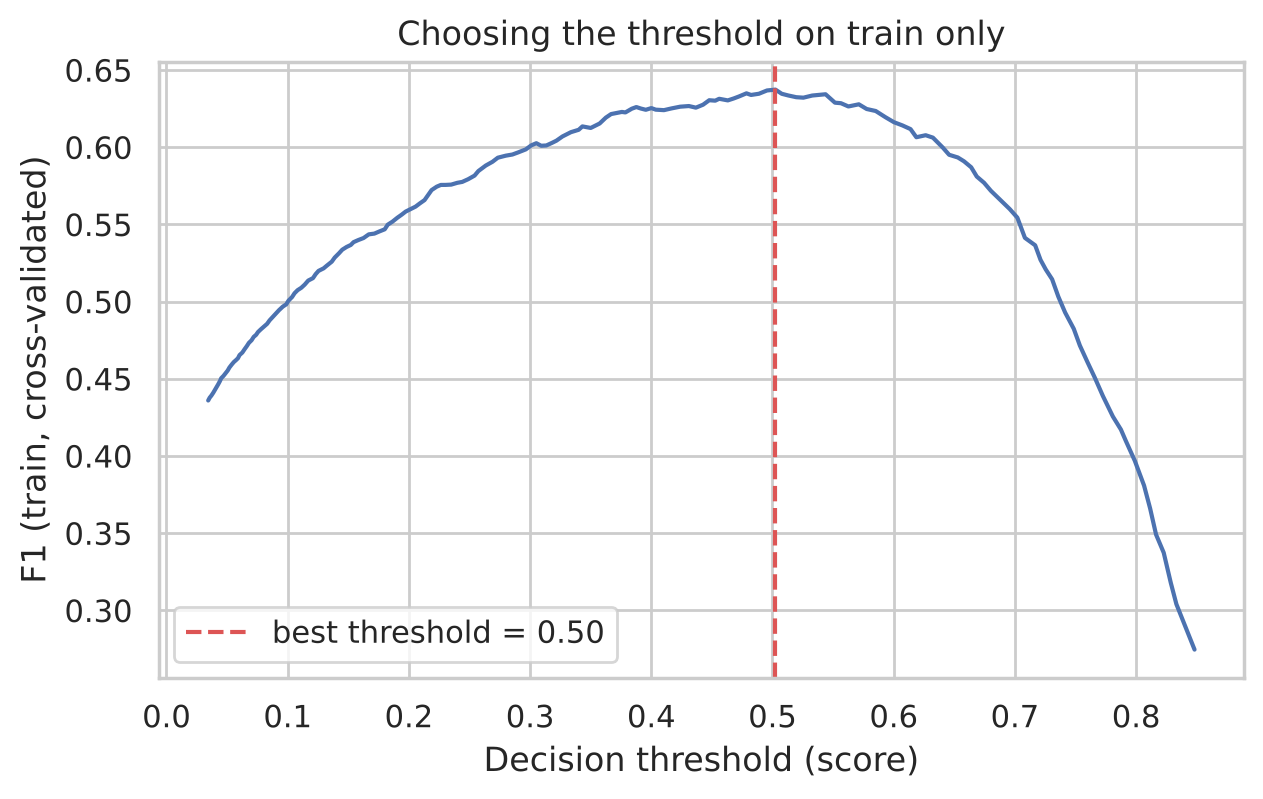

Chosen threshold: 0.502 | CV F1 at this threshold: 0.637


In [23]:
# Tuning B: choose the decision threshold from cross-validated predictions on TRAIN only
method = "predict_proba" if hasattr(tuned_model, "predict_proba") else "decision_function"
oof = cross_val_predict(tuned_model, X_train_p, y_train, cv=cv, method=method)
oof_scores = oof[:, 1] if method == "predict_proba" else oof

candidates = np.unique(np.quantile(oof_scores, np.linspace(0.05, 0.95, 181)))
f1_per_thr = np.array([f1_score(y_train, (oof_scores >= t).astype(int)) for t in candidates])
best_threshold = candidates[int(np.argmax(f1_per_thr))]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(candidates, f1_per_thr, color="#4C72B0")
ax.axvline(best_threshold, color="#DD5555", linestyle="--", label=f"best threshold = {best_threshold:.2f}")
ax.set_xlabel("Decision threshold (score)"); ax.set_ylabel("F1 (train, cross-validated)")
ax.set_title("Choosing the threshold on train only"); ax.legend()
plt.show()
print("Chosen threshold: %.3f | CV F1 at this threshold: %.3f" % (best_threshold, f1_per_thr.max()))

In [24]:
# Compare the three versions on the VALIDATION set
versions = {
    "1) Default settings": (models[best_name], None),
    "2) Grid search": (tuned_model, None),
    "3) Grid search + threshold": (tuned_model, best_threshold),
}
comparison = pd.DataFrame({name: evaluate(m, X_val_p, y_val, thr) for name, (m, thr) in versions.items()})
print(f"Validation results for {best_name}:")
comparison.round(3)

Validation results for Logistic Regression:


,1) Default settings,2) Grid search,3) Grid search + threshold
Accuracy,0.750,0.788,0.789
Precision,0.518,0.578,0.580
Recall,0.826,0.743,0.743
F1,0.637,0.650,0.652
ROC-AUC,0.862,0.861,0.861


In [25]:
# Keep the version with the best validation F1 (ties -> the simpler version, listed first)
final_version = comparison.loc["F1"].idxmax()
final_model, final_threshold = versions[final_version]
print("Selected version:", final_version)

before = comparison["1) Default settings"]
after = comparison[final_version]
change = (after - before).rename("Change")
print("\nBefore vs. after tuning (validation):")
pd.DataFrame({"Before tuning": before, "After tuning": after, "Change": change}).round(3)

Selected version: 3) Grid search + threshold

Before vs. after tuning (validation):


,Before tuning,After tuning,Change
Accuracy,0.750,0.789,0.039
Precision,0.518,0.580,0.062
Recall,0.826,0.743,-0.083
F1,0.637,0.652,0.015
ROC-AUC,0.862,0.861,-0.001


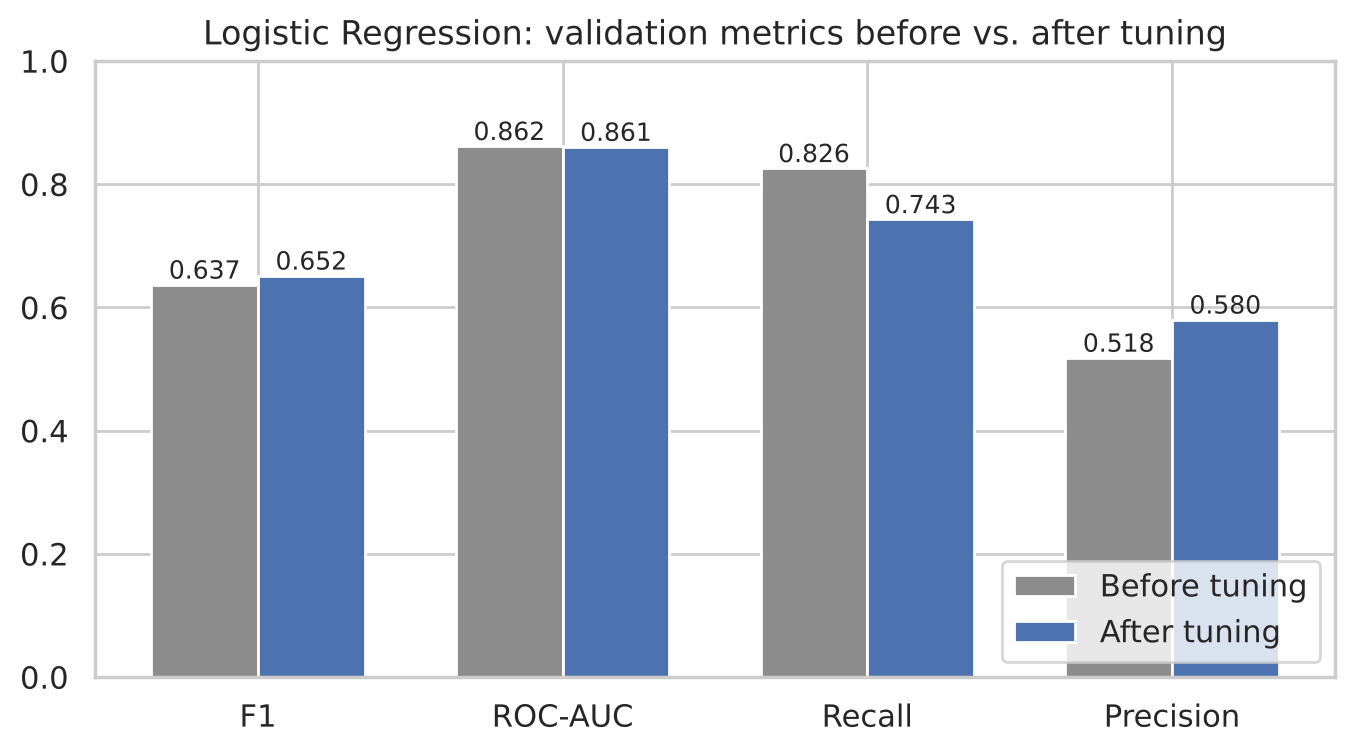

In [26]:
metrics_to_plot = ["F1", "ROC-AUC", "Recall", "Precision"]
x = np.arange(len(metrics_to_plot)); w = 0.35
fig, ax = plt.subplots(figsize=(8, 4))
b1 = ax.bar(x - w/2, [before[m] for m in metrics_to_plot], w, label="Before tuning", color="#8C8C8C")
b2 = ax.bar(x + w/2, [after[m] for m in metrics_to_plot], w, label="After tuning", color="#4C72B0")
ax.bar_label(b1, fmt="%.3f", fontsize=9); ax.bar_label(b2, fmt="%.3f", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(metrics_to_plot); ax.set_ylim(0, 1)
ax.set_title(f"{best_name}: validation metrics before vs. after tuning"); ax.legend(loc="lower right")
plt.show()

**Tuning result (Logistic Regression, validation set)**
- GridSearch chose stronger regularization (`C = 0.03`) and a lower weight for the churn class (`{0: 1, 1: 2}` instead of fully balanced).
- **F1 improved from 0.637 to 0.652 (+0.015)**. Precision improved from 0.518 to 0.580 and accuracy from 0.750 to 0.789. Recall went down from 0.826 to 0.743: the tuned model makes **fewer false alarms** but misses **more churners**.
- ROC-AUC is the same (~0.86). This is expected: tuning mostly changed the balance between precision and recall, not the ranking quality of the model.
- The threshold step added only a tiny gain (0.650 -> 0.652), because the default threshold was already almost optimal after the grid search.
- **Honest note:** the improvement is real but small. Logistic Regression has few hyperparameters, and the information in this dataset is limited.

## 1️⃣1️⃣ Final Testing

Now we use the **test set for the first and only time**. We evaluate the final model (the version selected above).

In [27]:
test_scores = evaluate(final_model, X_test_p, y_test, final_threshold)
final_table = pd.DataFrame({"Validation": after, "Test": test_scores})
print("Final model:", best_name, "|", final_version)
final_table.round(3)

Final model: Logistic Regression | 3) Grid search + threshold


,Validation,Test
Accuracy,0.789,0.768
Precision,0.580,0.549
Recall,0.743,0.703
F1,0.652,0.617
ROC-AUC,0.861,0.840


In [28]:
test_scores_raw = get_scores(final_model, X_test_p)
test_pred = final_model.predict(X_test_p) if final_threshold is None else (test_scores_raw >= final_threshold).astype(int)
print(classification_report(y_test, test_pred, target_names=["Stayed (0)", "Churned (1)"]))

              precision    recall  f1-score   support

  Stayed (0)       0.88      0.79      0.83      1035
 Churned (1)       0.55      0.70      0.62       374

    accuracy                           0.77      1409
   macro avg       0.71      0.75      0.73      1409
weighted avg       0.79      0.77      0.78      1409



### Bonus: Confusion matrix and ROC curve

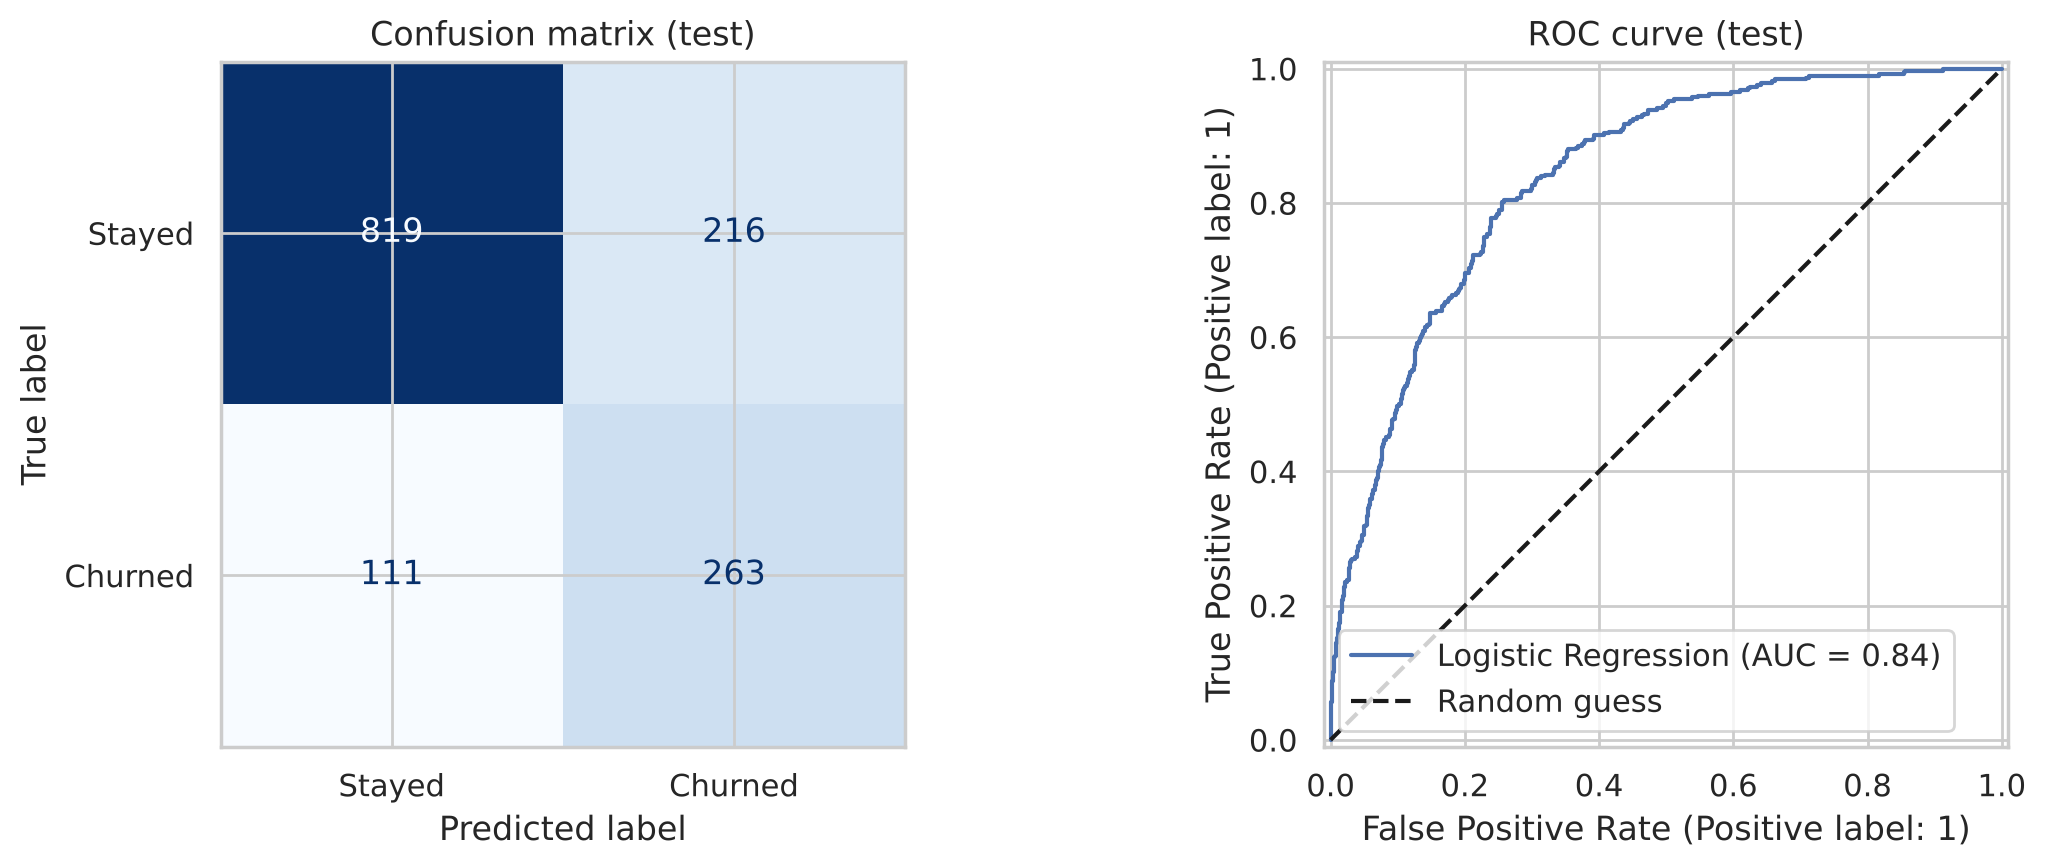

True churners caught: 263 | missed churners: 111 | false alarms: 216 | correct 'stay': 819


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Stayed", "Churned"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix (test)")
RocCurveDisplay.from_predictions(y_test, test_scores_raw, ax=axes[1], name=best_name)
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess"); axes[1].legend()
axes[1].set_title("ROC curve (test)")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
print(f"True churners caught: {tp} | missed churners: {fn} | false alarms: {fp} | correct 'stay': {tn}")

### Bonus: Feature importance

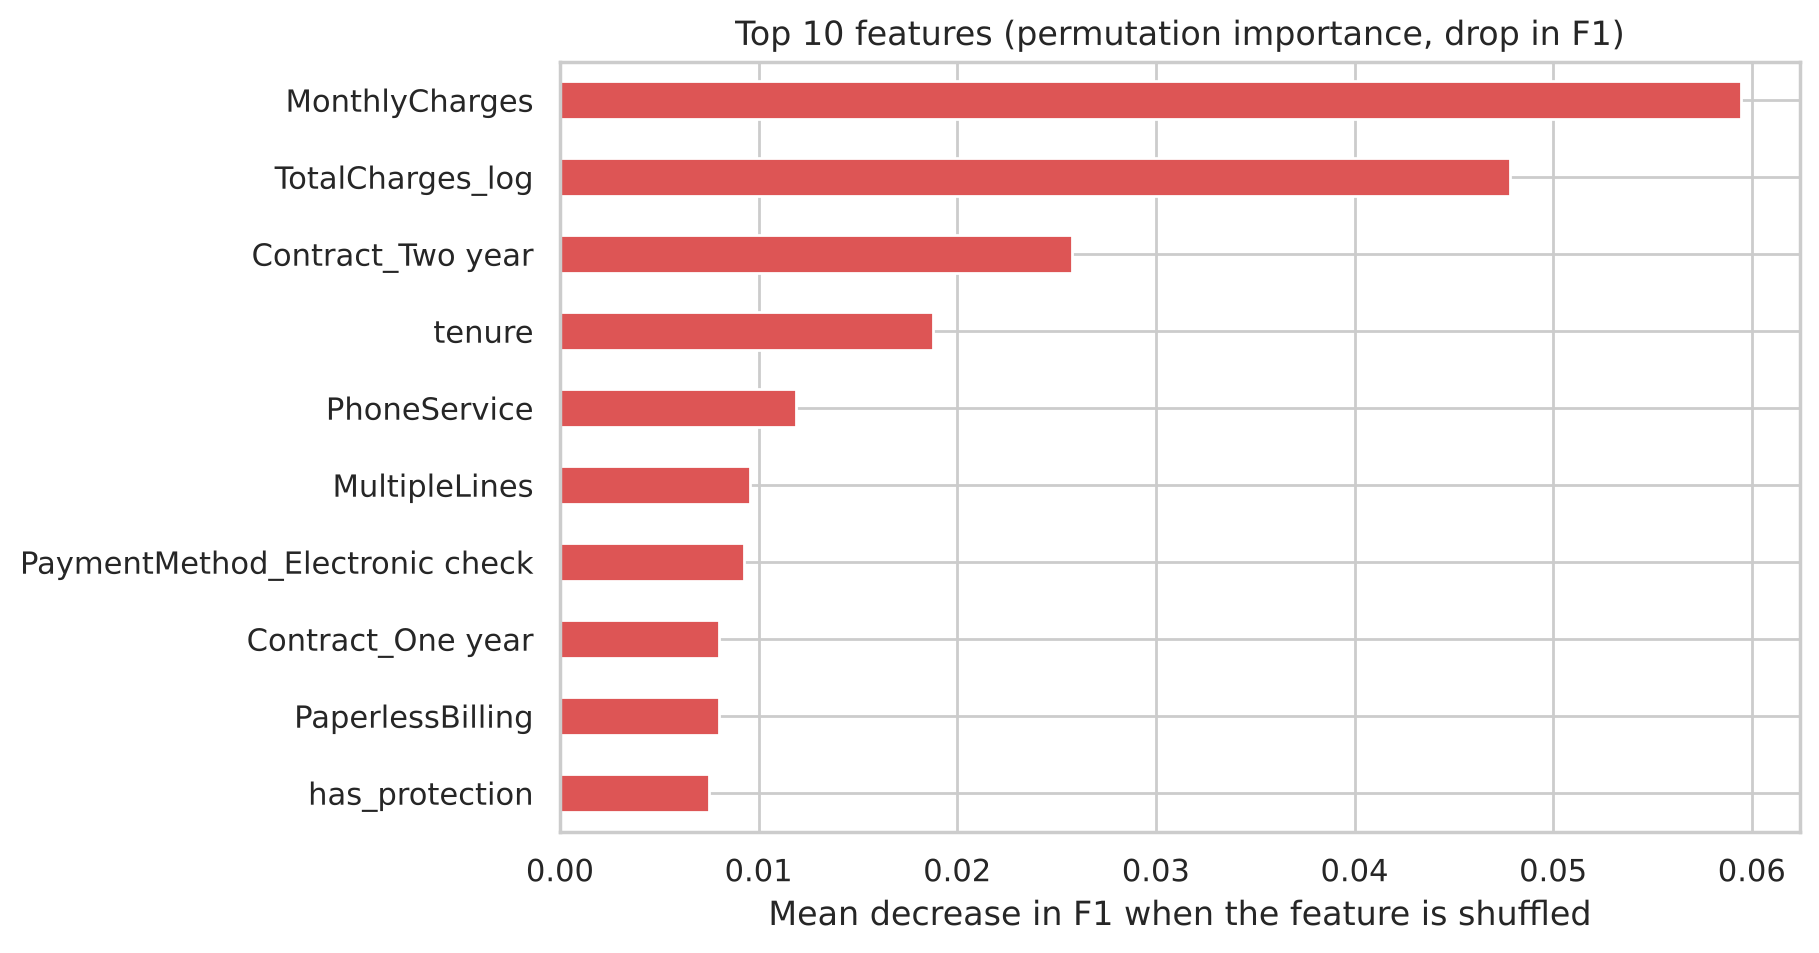

MonthlyCharges                    0.0595
TotalCharges_log                  0.0478
Contract_Two year                 0.0258
tenure                            0.0188
PhoneService                      0.0119
MultipleLines                     0.0096
PaymentMethod_Electronic check    0.0093
Contract_One year                 0.0080
PaperlessBilling                  0.0080
has_protection                    0.0075
dtype: float64

In [30]:
# Permutation importance on the VALIDATION set (the test set stays untouched)
def f1_scorer(est, X, y):
    s = get_scores(est, X)
    pred = est.predict(X) if final_threshold is None else (s >= final_threshold).astype(int)
    return f1_score(y, pred)

perm = permutation_importance(final_model, X_val_p, y_val, scoring=f1_scorer,
                              n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_val_p.columns).sort_values(ascending=False)

top = importance.head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
top.plot(kind="barh", color="#DD5555", ax=ax)
ax.set_title("Top 10 features (permutation importance, drop in F1)")
ax.set_xlabel("Mean decrease in F1 when the feature is shuffled")
plt.show()
importance.head(10).round(4)

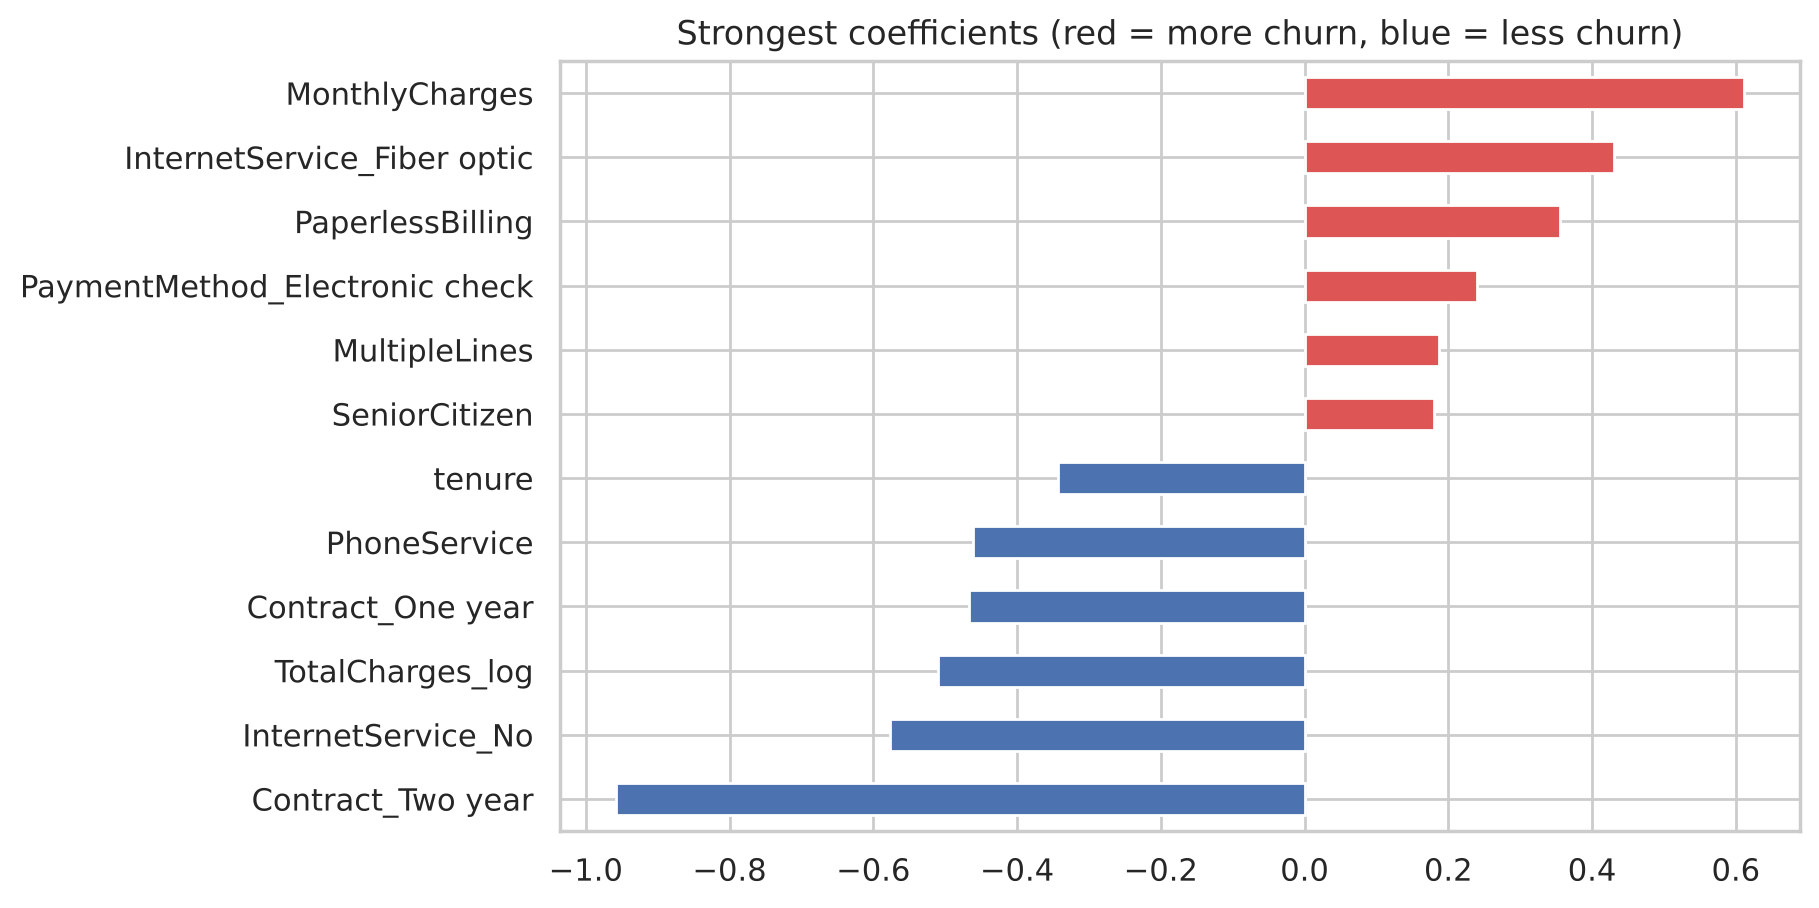

In [31]:
# Direction of the effect (only for linear models): positive coefficient = higher churn risk
if hasattr(final_model, "coef_"):
    coefs = pd.Series(final_model.coef_[0], index=X_train_p.columns).sort_values()
    show = pd.concat([coefs.head(6), coefs.tail(6)])
    fig, ax = plt.subplots(figsize=(8, 5))
    show.plot(kind="barh", color=["#4C72B0" if v < 0 else "#DD5555" for v in show], ax=ax)
    ax.set_title("Strongest coefficients (red = more churn, blue = less churn)")
    plt.show()

### Final insights, limitations and next steps

**Final result on the test set** (Logistic Regression, tuned): **F1 = 0.62**, **ROC-AUC = 0.84**, Precision = 0.55, Recall = 0.70, Accuracy = 0.77.
The model finds about **7 of every 10 churners** (263 of 374). A dummy model finds none.
The test F1 (0.617) is a little lower than the validation F1 (0.652). This is normal: we used the validation set to select and tune the model, so the validation score is slightly optimistic. The test score is the honest estimate.

**Insights**
- **More churn:** higher `MonthlyCharges`, fiber optic internet, paperless billing, electronic check payment, senior citizens.
- **Less churn:** two-year (strongest) and one-year contracts, longer tenure, no internet service.
- Permutation importance gives the same story: pricing (`MonthlyCharges`, `TotalCharges`), contract type and tenure are at the top. These features are correlated with each other, so read them as a **group**, not as an exact ranking.
- The simplest model won. Random Forest reached a train F1 of 0.99 but only 0.60 on validation (overfitting), so a more complex model is not always better.
- **Business action:** target month-to-month customers in their first year, especially fiber optic customers who pay by electronic check, and offer them a longer contract, automatic payment or tech support.

**Limitations**
- F1 is moderate (~0.62). About 45% of the customers we flag would have stayed (216 false alarms vs. 263 real churners caught).
- The test set has only 374 churners, so the metrics have some uncertainty. One split can give a slightly different result with another seed.
- The data has no reasons for leaving (complaints, competitor offers, price changes) and no behavior over time (it is a one-month snapshot).
- The threshold was chosen to maximize F1, not the real business cost.

**Next steps**
- Choose the threshold using the real cost of a retention offer vs. the value of a lost customer.
- Use repeated cross-validation for a more stable estimate, and try XGBoost / LightGBM.
- Add behavior data (usage, support tickets, billing changes over time).
- Before deployment, retrain the final model on train + validation.